# Parte Comum: K-Means no dataset Obesity

**Dataset:** *Estimation of obesity levels based on eating habits and physical condition* (Palechor & De la Hoz Manotas, 2019), UCI Machine Learning Repository, id 544. São 2.111 registros e 17 atributos, de pessoas do México, do Peru e da Colômbia.

**Roteiro**
1. EDA dos 4 pilares: estrutura, distribuições, relações e outliers.
2. Pré-processamento e padronização.
3. K-Means, passada 1: k de 2 a 10, escolhido pelo Método do Cotovelo.
4. K-Means, passada 2: k = 7, o número real de classes.
5. Em cada passada: mapear cluster → classe majoritária, montar a matriz de confusão e calcular acurácia, precisão e recall por classe.
6. Comparação das passadas e discussão crítica sobre as classes.

> O código deste notebook foi gerado com apoio de IA (Claude) e está marcado com `# [IA] Claude`. O grupo revisou o código e os resultados. Ver `docs/DECLARACAO_IA.pdf`.

In [1]:
# [IA] Claude: imports, caminhos e configuração
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, silhouette_score)

SEED = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Funciona tanto a partir de notebooks/parte_comum/ quanto da raiz do repositório
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "parte_comum").exists()), Path.cwd())
CSV = RAIZ / "data" / "parte_comum" / "ObesityDataSet_raw_and_data_sinthetic.csv"
OUT = RAIZ / "out" / "parte_comum"
FIG = OUT / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

if CSV.exists():
    df_raw = pd.read_csv(CSV)
else:  # Colab sem o repositório: baixa direto da UCI
    import io, urllib.request, zipfile
    url = ("https://archive.ics.uci.edu/static/public/544/estimation+of+obesity+levels"
           "+based+on+eating+habits+and+physical+condition.zip")
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        df_raw = pd.read_csv(z.open("ObesityDataSet_raw_and_data_sinthetic.csv"))

ALVO = "NObeyesdad"
ORDEM_CLASSES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
                 "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
print(df_raw.shape)
df_raw.head()

(2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 1. EDA, pilar 1: estrutura

O dicionário abaixo traduz as siglas do dataset.

| Atributo | Significado | Tipo |
|---|---|---|
| Gender, Age, Height (m), Weight (kg) | sexo, idade, altura e peso | demográfico e físico |
| family_history_with_overweight | histórico familiar de sobrepeso | binário |
| FAVC | consome alimentos muito calóricos com frequência | binário |
| FCVC | frequência de consumo de vegetais (1 a 3) | ordinal |
| NCP | número de refeições principais por dia (1 a 4) | ordinal |
| CAEC | come entre as refeições (no, Sometimes, Frequently, Always) | ordinal |
| SMOKE | fuma | binário |
| CH2O | consumo diário de água (1 a 3) | ordinal |
| SCC | monitora as calorias | binário |
| FAF | frequência de atividade física (0 a 3) | ordinal |
| TUE | tempo diário em dispositivos eletrônicos (0 a 2) | ordinal |
| CALC | consumo de álcool (no, Sometimes, Frequently, Always) | ordinal |
| MTRANS | meio de transporte | nominal |
| **NObeyesdad** | **nível de obesidade, o rótulo de classe (7 classes)** | alvo |

In [2]:
# [IA] Claude: tipos, ausentes, duplicatas e cardinalidade
estrutura = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_ausentes": df_raw.isna().sum(),
    "n_unicos": df_raw.nunique(),
    "exemplo": df_raw.iloc[0],
})
estrutura.to_csv(OUT / "estrutura.csv")
print("Linhas duplicadas:", df_raw.duplicated().sum())
print("Valores ausentes no total:", df_raw.isna().sum().sum())
estrutura

Linhas duplicadas: 24
Valores ausentes no total: 0


,dtype,n_ausentes,n_unicos,exemplo
Gender,object,0,2,Female
Age,float64,0,1402,21.0
Height,float64,0,1574,1.62
Weight,float64,0,1525,64.0
family_history_with_overweight,object,0,2,yes
FAVC,object,0,2,no
FCVC,float64,0,810,2.0
NCP,float64,0,635,3.0
CAEC,object,0,4,Sometimes
SMOKE,object,0,2,no


In [3]:
# [IA] Claude: atributos ordinais que deveriam ser inteiros, mas têm casas decimais
ordinais_num = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
frac_nao_inteiro = {c: (df_raw[c] % 1 != 0).mean() for c in ordinais_num + ["Age"]}
pd.Series(frac_nao_inteiro, name="% de valores não inteiros").mul(100).round(1)

FCVC    39.1
NCP     30.3
CH2O    61.1
FAF     57.2
TUE     54.6
Age     65.1
Name: % de valores não inteiros, dtype: float64

**O que a estrutura mostra**
- 2.111 linhas e 17 colunas: 8 numéricas e 9 categóricas. **Não há valores ausentes.**
- Há **24 linhas duplicadas**. Elas são removidas, porque contam duas vezes no cálculo dos centróides.
- Os autores informam que **77% dos registros são sintéticos**, gerados com SMOTE no Weka para balancear as classes. Só 23% vieram do questionário online. Isso explica dois fatos:
  - as respostas ordinais (FCVC, NCP, CH2O, FAF e TUE) e a idade aparecem com casas decimais, como em FCVC = 2,39, que não é uma resposta possível;
  - as 7 classes têm tamanhos quase iguais (entre 272 e 351), o que não corresponde à prevalência real de obesidade.
- O rótulo NObeyesdad foi definido pelo **IMC = peso / altura²**, segundo as faixas da OMS. Na prática, então, a classe é uma função de duas colunas do próprio dataset.

In [4]:
# [IA] Claude: remoção de duplicatas e criação do IMC (usado só na EDA e na análise complementar)
df = df_raw.drop_duplicates().reset_index(drop=True)
df["IMC"] = df["Weight"] / df["Height"] ** 2
print(df.shape)

(2087, 18)


## 2. EDA, pilar 2: distribuições

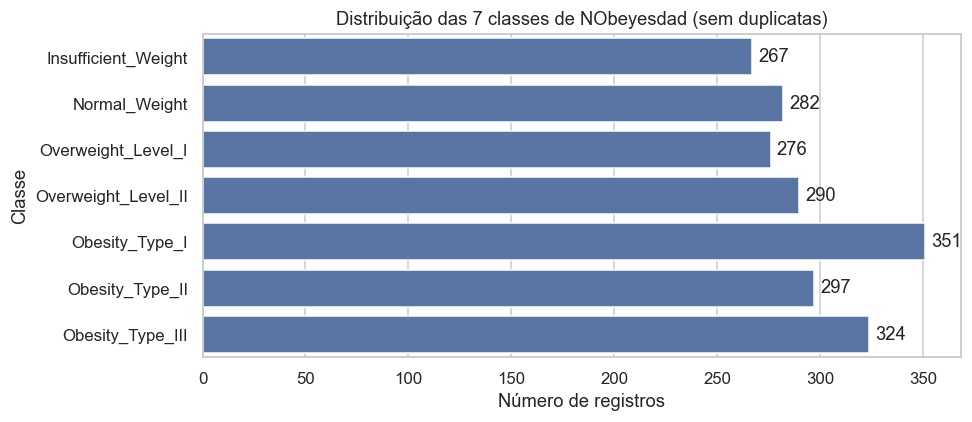

In [5]:
# [IA] Claude: distribuição da classe
fig, ax = plt.subplots(figsize=(9, 4))
cont = df[ALVO].value_counts().reindex(ORDEM_CLASSES)
sns.barplot(x=cont.values, y=cont.index, ax=ax, color="#4C72B0")
for i, v in enumerate(cont.values):
    ax.text(v + 3, i, str(v), va="center")
ax.set(title="Distribuição das 7 classes de NObeyesdad (sem duplicatas)",
       xlabel="Número de registros", ylabel="Classe")
plt.tight_layout(); plt.savefig(FIG / "C1_classes.png"); plt.show()

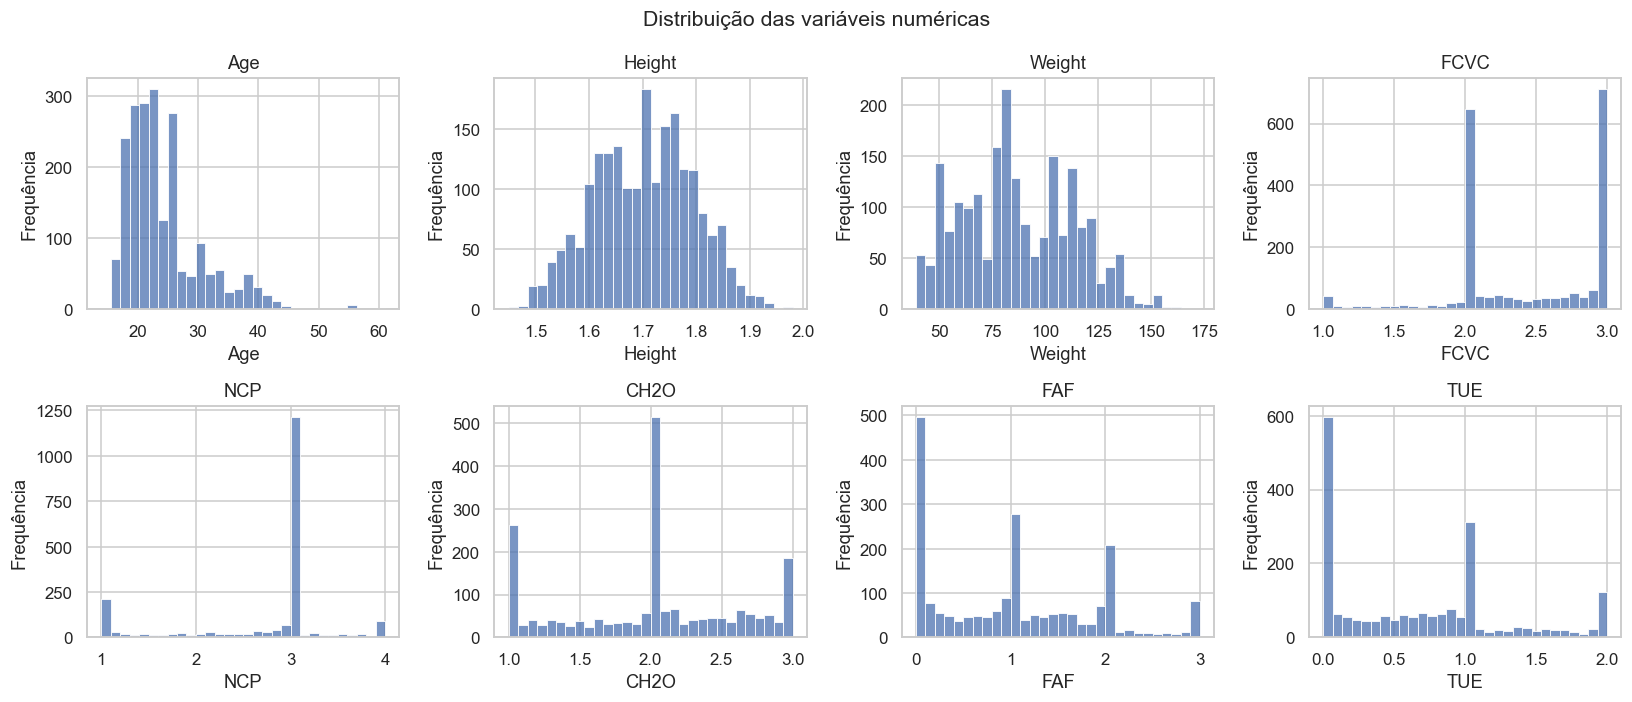

,count,mean,std,min,25%,50%,75%,max,assimetria
Age,2087.0,24.35,6.37,14.00,19.92,22.85,26.00,61.00,1.51
Height,2087.0,1.70,0.09,1.45,1.63,1.70,1.77,1.98,-0.02
Weight,2087.0,86.86,26.19,39.00,66.00,83.10,108.02,173.00,0.24
FCVC,2087.0,2.42,0.53,1.00,2.00,2.40,3.00,3.00,-0.45
NCP,2087.0,2.70,0.76,1.00,2.70,3.00,3.00,4.00,-1.14
CH2O,2087.0,2.00,0.61,1.00,1.59,2.00,2.47,3.00,-0.11
FAF,2087.0,1.01,0.85,0.00,0.12,1.00,1.68,3.00,0.49
TUE,2087.0,0.66,0.61,0.00,0.00,0.63,1.00,2.00,0.61
IMC,2087.0,29.77,8.02,13.00,24.37,28.90,36.10,50.81,0.14


In [6]:
# [IA] Claude: histogramas das variáveis numéricas
NUM = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.flat, NUM):
    sns.histplot(df[c], bins=30, ax=ax, color="#4C72B0")
    ax.set(title=c, xlabel=c, ylabel="Frequência")
fig.suptitle("Distribuição das variáveis numéricas", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "C2_histogramas.png"); plt.show()

desc = df[NUM + ["IMC"]].describe().T
desc["assimetria"] = df[NUM + ["IMC"]].skew()
desc.round(2).to_csv(OUT / "descritiva_numerica.csv")
desc.round(2)

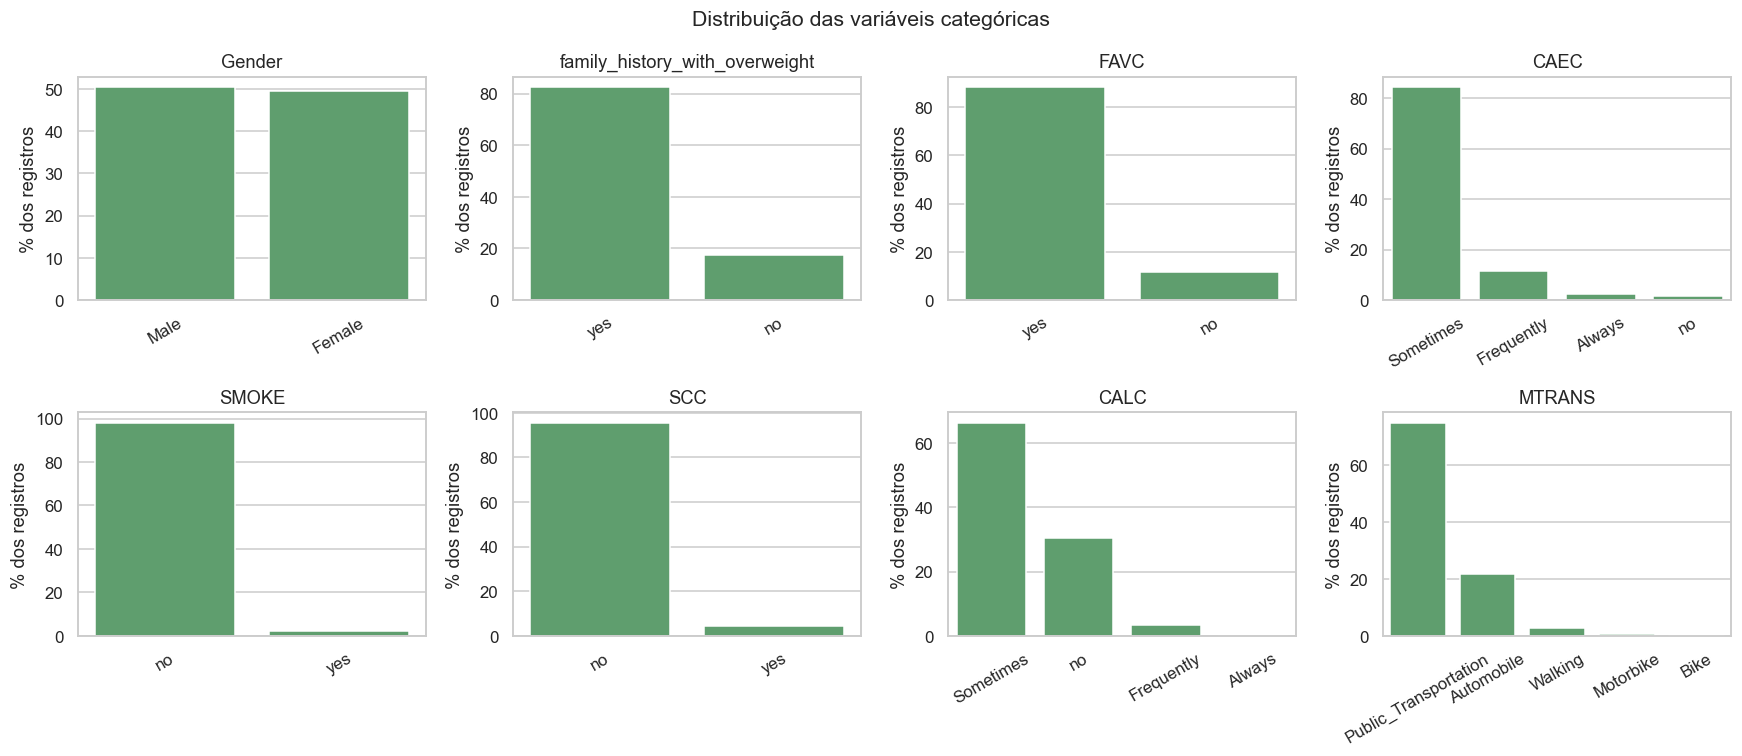

In [7]:
# [IA] Claude: frequências das variáveis categóricas
CAT = ["Gender", "family_history_with_overweight", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, CAT):
    vc = df[c].value_counts(normalize=True).mul(100)
    sns.barplot(x=vc.index, y=vc.values, ax=ax, color="#55A868")
    ax.set(title=c, xlabel="", ylabel="% dos registros")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Distribuição das variáveis categóricas", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "C3_categoricas.png"); plt.show()

**O que as distribuições mostram**
- **Age** é assimétrica à direita: a maioria tem entre 18 e 26 anos e a cauda vai até 61. A amostra é jovem.
- **Weight** é larga, de 39 a 173 kg, com vários picos, um efeito das classes balanceadas. **Height** é quase simétrica.
- As ordinais (**FCVC, NCP, CH2O, FAF e TUE**) concentram valores nos inteiros 1, 2 e 3, com uma "nuvem" de decimais entre eles, que é a marca do SMOTE.
- Nas categóricas, **SMOKE** e **SCC** são muito raras, com menos de 5% de "yes". A maioria tem histórico familiar de sobrepeso e consome alimentos calóricos (FAVC). Em **MTRANS** predominam o transporte público e o automóvel.

## 3. EDA, pilar 3: relações

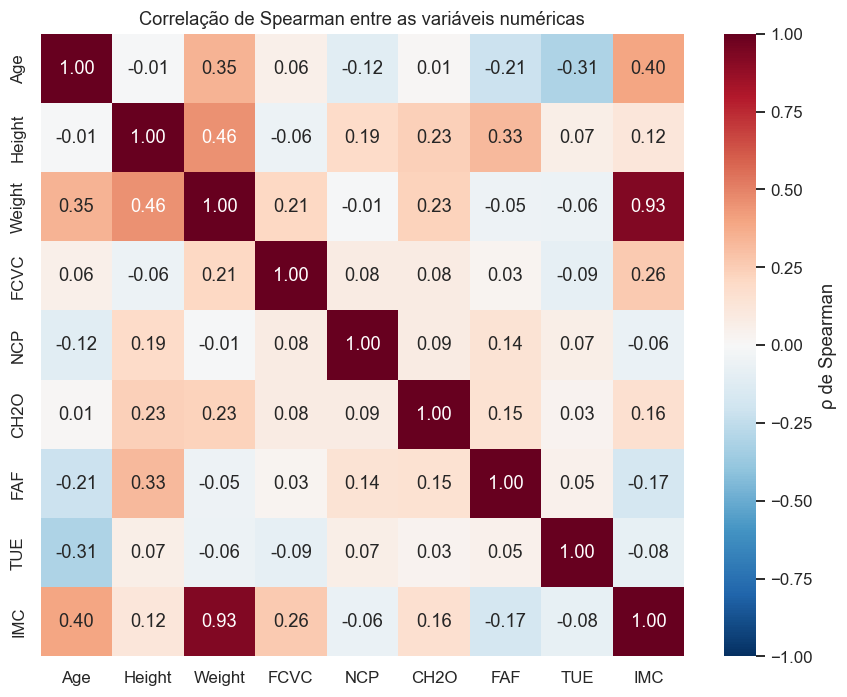

In [8]:
# [IA] Claude: correlação de Spearman entre as numéricas
corr = df[NUM + ["IMC"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "ρ de Spearman"})
ax.set_title("Correlação de Spearman entre as variáveis numéricas")
plt.tight_layout(); plt.savefig(FIG / "C4_correlacao.png"); plt.show()
corr.round(3).to_csv(OUT / "correlacao_spearman.csv")

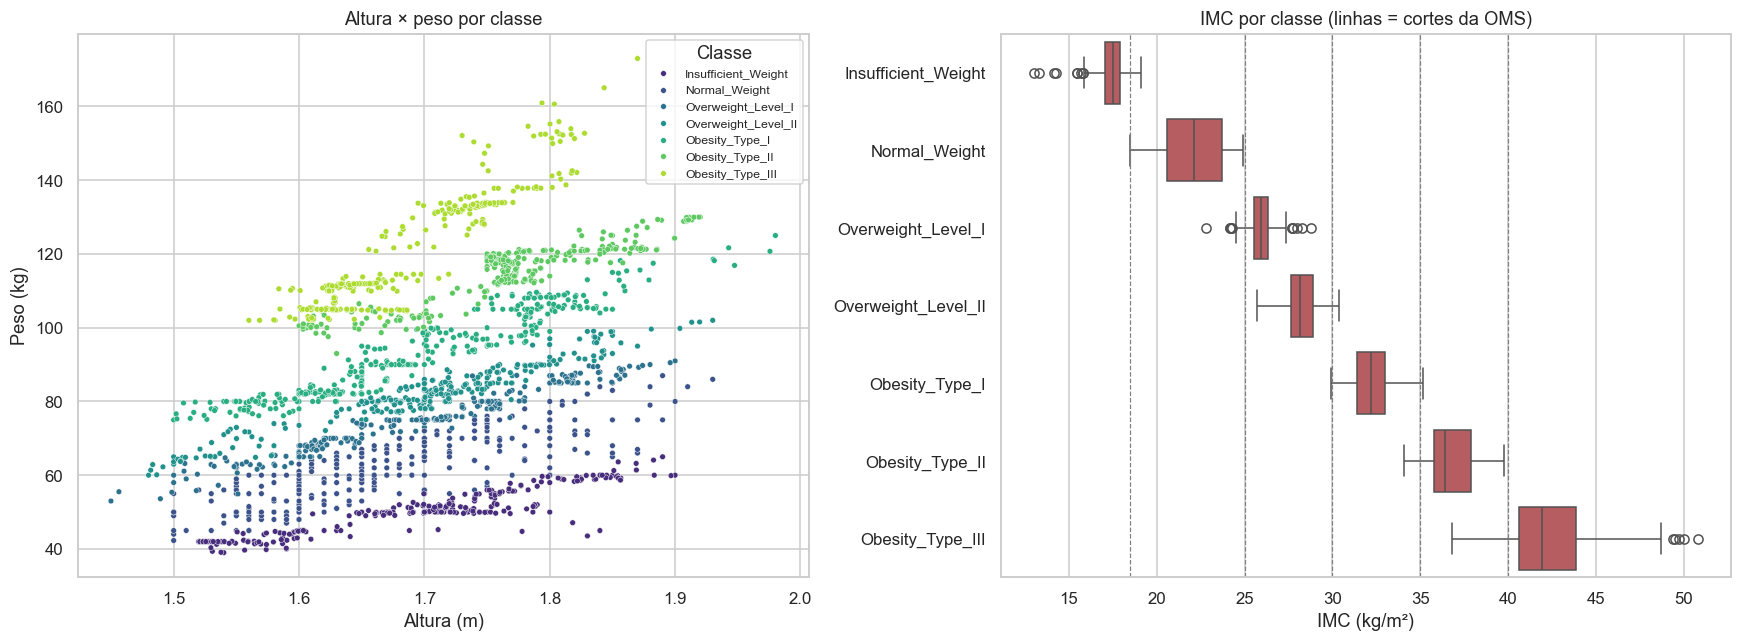

,min,median,max
NObeyesdad,,,
Insufficient_Weight,13.0,17.5,19.1
Normal_Weight,18.5,22.1,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.2,30.4
Obesity_Type_I,29.9,32.2,35.2
Obesity_Type_II,34.0,36.4,39.8
Obesity_Type_III,36.8,41.9,50.8


In [9]:
# [IA] Claude: altura × peso colorido pela classe e IMC por classe
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df, x="Height", y="Weight", hue=ALVO, hue_order=ORDEM_CLASSES,
                palette="viridis", s=14, ax=axes[0])
axes[0].set(title="Altura × peso por classe", xlabel="Altura (m)", ylabel="Peso (kg)")
axes[0].legend(title="Classe", fontsize=8)
sns.boxplot(data=df, y=ALVO, x="IMC", order=ORDEM_CLASSES, ax=axes[1], color="#C44E52")
for lim in [18.5, 25, 30, 35, 40]:
    axes[1].axvline(lim, ls="--", c="gray", lw=0.8)
axes[1].set(title="IMC por classe (linhas = cortes da OMS)", xlabel="IMC (kg/m²)", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "C5_altura_peso_imc.png"); plt.show()

imc_classe = df.groupby(ALVO)["IMC"].agg(["min", "median", "max"]).reindex(ORDEM_CLASSES).round(1)
imc_classe.to_csv(OUT / "imc_por_classe.csv")
imc_classe

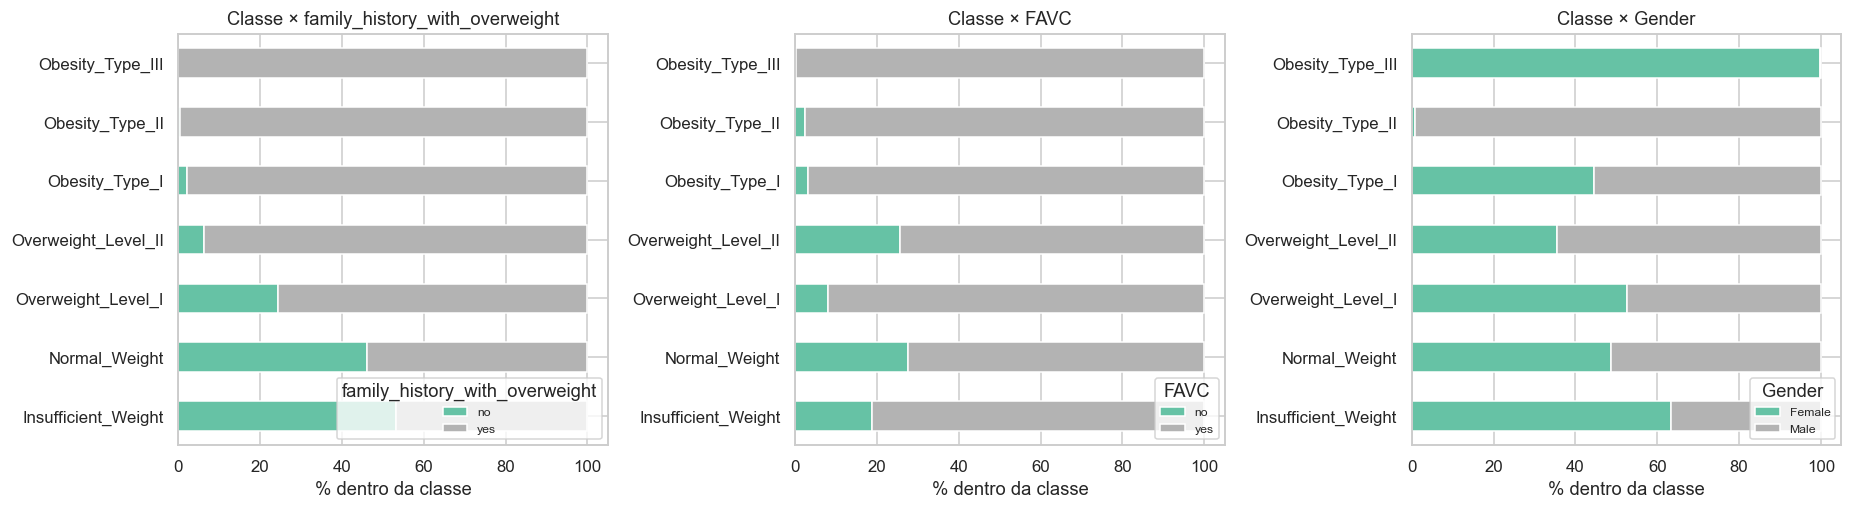

In [10]:
# [IA] Claude: classe × variáveis categóricas mais associadas (proporção por linha)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, c in zip(axes, ["family_history_with_overweight", "FAVC", "Gender"]):
    tab = pd.crosstab(df[ALVO], df[c], normalize="index").reindex(ORDEM_CLASSES).mul(100)
    tab.plot(kind="barh", stacked=True, ax=ax, colormap="Set2", legend=True)
    ax.set(title=f"Classe × {c}", xlabel="% dentro da classe", ylabel="")
    ax.legend(title=c, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "C6_classe_categoricas.png"); plt.show()

**O que as relações mostram**
- **Weight** é a variável mais associada ao IMC (ρ ≈ 0,93). Age tem associação moderada (ρ ≈ 0,40) e Height, fraca (ρ ≈ 0,12). Os hábitos (FCVC, FAF, CH2O, TUE) têm correlações baixas, abaixo de 0,3 em módulo, entre si e com o IMC.
- No gráfico altura × peso, as classes formam **faixas diagonais**, as curvas de IMC constante. As faixas vizinhas **se tocam e se sobrepõem**.
- No boxplot do IMC, as classes seguem a ordem esperada, mas há **sobreposição entre classes vizinhas**. Overweight_Level_I e Overweight_Level_II, por exemplo, dividem a faixa de 25,7 a 28,8, e Obesity_Type_II e Obesity_Type_III dividem a faixa de 36,8 a 39,8. Os registros sintéticos interpolados entre classes vizinhas são a explicação provável.
- Histórico familiar e FAVC crescem nas classes de obesidade. **Obesity_Type_II é quase só masculina e Obesity_Type_III quase só feminina**, um viés da amostra.

## 4. EDA, pilar 4: outliers

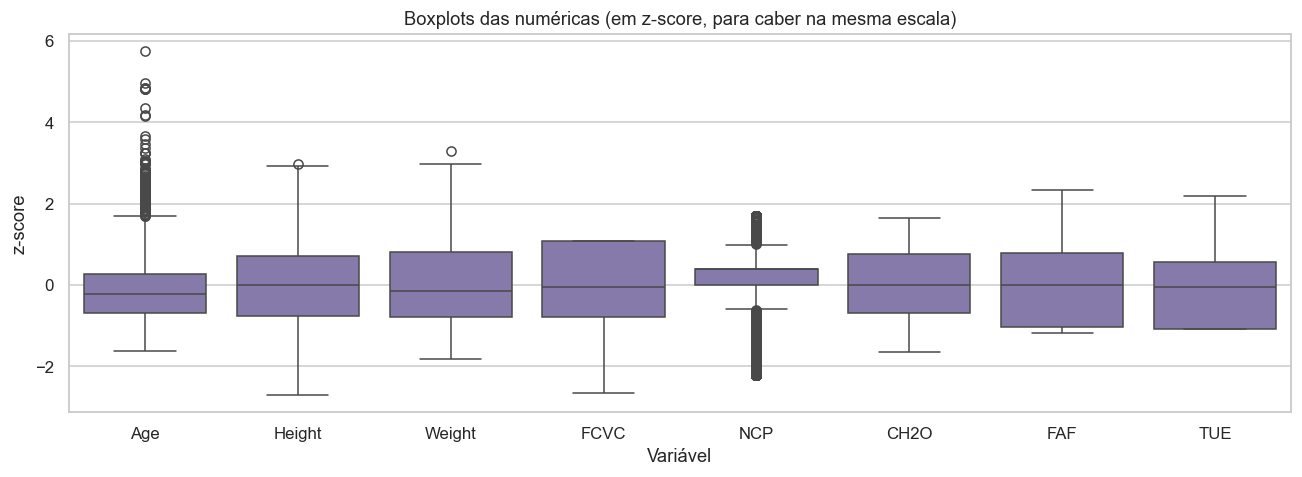

,n_outliers,min,max,%
Age,167,14.00,61.00,8.00
Height,1,1.45,1.98,0.05
Weight,1,39.00,173.00,0.05
FCVC,0,1.00,3.00,0.00
NCP,577,1.00,4.00,27.65
CH2O,0,1.00,3.00,0.00
FAF,0,0.00,3.00,0.00
TUE,0,0.00,2.00,0.00


In [11]:
# [IA] Claude: triagem de outliers pelo critério IQR (1,5 × IQR)
def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out_tab = pd.DataFrame({
    "n_outliers": {c: outliers_iqr(df[c]) for c in NUM},
    "min": df[NUM].min(), "max": df[NUM].max(),
})
out_tab["%"] = (out_tab.n_outliers / len(df) * 100).round(2)
out_tab.to_csv(OUT / "outliers_iqr.csv")

fig, ax = plt.subplots(figsize=(12, 4.5))
z = (df[NUM] - df[NUM].mean()) / df[NUM].std()
sns.boxplot(data=z, ax=ax, color="#8172B2")
ax.set(title="Boxplots das numéricas (em z-score, para caber na mesma escala)",
       xlabel="Variável", ylabel="z-score")
plt.tight_layout(); plt.savefig(FIG / "C7_outliers.png"); plt.show()
out_tab

**Decisão sobre outliers**
- Os outliers do IQR se concentram em **Age**, com idades acima de cerca de 35 anos numa amostra jovem, e em **NCP**, que fica quase sempre em 3, então qualquer outro valor vira "outlier". Peso e altura têm pouquíssimos.
- Todos os valores são **plausíveis**: não existe idade de 200 nem altura de 3 m. Eles não são erro de digitação, e sim pessoas reais menos frequentes.
- **Decisão: manter.** Removê-los apagaria grupos reais, como as pessoas mais velhas. O K-Means é sensível a extremos, mas a padronização reduz o peso de cada um, e a fração de outliers é pequena.

## 5. Pré-processamento e padronização

**Codificação**
- Binárias (Gender, family_history, FAVC, SMOKE e SCC) viram 0 ou 1.
- Ordinais (CAEC e CALC) viram no = 0, Sometimes = 1, Frequently = 2 e Always = 3.
- MTRANS, que é nominal, passa por one-hot: uma coluna 0/1 por meio de transporte.
- O alvo **NObeyesdad sai** da matriz de atributos e o IMC não entra, porque o K-Means é não supervisionado. O rótulo só volta depois, para avaliar os clusters.

**Por que o K-Means precisa de padronização.** O K-Means agrupa os pontos pela **distância euclidiana** até os centróides. Quando as variáveis estão em escalas diferentes, a variável com maior amplitude domina a distância. Aqui, o desvio-padrão do peso (≈ 26 kg) é cerca de 280 vezes o da altura (≈ 0,09 m). Sem padronizar, o algoritmo agruparia praticamente só pelo peso, e altura, hábitos e idade não fariam diferença. O `StandardScaler` transforma cada coluna em z = (x − média) / desvio-padrão, com média 0 e desvio 1, e assim todas as variáveis passam a contribuir na mesma escala.

In [12]:
# [IA] Claude: codificação
X = df.drop(columns=[ALVO, "IMC"]).copy()
for c in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    X[c] = (X[c] == "yes").astype(int)
X["Gender"] = (X["Gender"] == "Male").astype(int)
ORD = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
X["CAEC"] = X["CAEC"].map(ORD)
X["CALC"] = X["CALC"].map(ORD)
X = pd.get_dummies(X, columns=["MTRANS"], dtype=int)
y = df[ALVO]
print(X.shape)

# [IA] Claude: padronização
scaler = StandardScaler()
Z = scaler.fit_transform(X)

antes_depois = pd.DataFrame({
    "desvio_antes": X.std(), "desvio_depois": pd.DataFrame(Z, columns=X.columns).std(),
    "media_depois": pd.DataFrame(Z, columns=X.columns).mean().round(6),
}).round(3)
antes_depois

(2087, 20)


,desvio_antes,desvio_depois,media_depois
Gender,0.500,1.0,0.0
Age,6.369,1.0,-0.0
Height,0.093,1.0,0.0
Weight,26.191,1.0,-0.0
family_history_with_overweight,0.380,1.0,-0.0
FAVC,0.321,1.0,-0.0
FCVC,0.535,1.0,-0.0
NCP,0.765,1.0,0.0
CAEC,0.459,1.0,0.0
SMOKE,0.144,1.0,0.0


## 6. Funções de avaliação

Os clusters do K-Means não têm nome, apenas números de 0 a k−1. Para comparar com as classes reais:
1. **Mapeamento:** cada cluster recebe a **classe majoritária** entre os seus membros.
2. Todo ponto passa a ter uma "classe prevista", a classe do seu cluster.
3. Com a classe prevista, calculamos a matriz de confusão (real × prevista), a acurácia e a precisão e o recall de cada classe.

Quando k < 7, ou quando dois clusters têm a mesma classe majoritária, algumas classes **nunca são previstas**. Nesse caso a precisão delas é indefinida (registrada como 0) e o recall é 0.

In [13]:
# [IA] Claude: funções reutilizadas nas duas passadas
def mapear_clusters(rotulos, y):
    tab = pd.crosstab(pd.Series(rotulos, name="cluster"), y)
    return tab, tab.idxmax(axis=1)

def avaliar(k, Z, y, nome):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    tab, mapa = mapear_clusters(km.labels_, y)
    y_pred = pd.Series(km.labels_, index=y.index).map(mapa)

    metr = pd.DataFrame({
        "precisao": precision_score(y, y_pred, labels=ORDEM_CLASSES, average=None, zero_division=0),
        "recall": recall_score(y, y_pred, labels=ORDEM_CLASSES, average=None, zero_division=0),
        "suporte": y.value_counts().reindex(ORDEM_CLASSES).values,
        "prevista_por_algum_cluster": [c in set(mapa) for c in ORDEM_CLASSES],
    }, index=ORDEM_CLASSES).round(3)
    acc = accuracy_score(y, y_pred)

    # composição dos clusters
    tab_out = tab.reindex(columns=ORDEM_CLASSES)
    tab_out["classe_majoritaria"] = mapa
    tab_out["pureza"] = (tab.max(axis=1) / tab.sum(axis=1)).round(3)
    tab_out.to_csv(OUT / f"{nome}_composicao_clusters.csv")
    metr.to_csv(OUT / f"{nome}_metricas.csv")

    # matriz de confusão
    cm = confusion_matrix(y, y_pred, labels=ORDEM_CLASSES)
    fig, ax = plt.subplots(figsize=(8.5, 7))
    curtos = ["Insuf.", "Normal", "Sobrep. I", "Sobrep. II", "Obes. I", "Obes. II", "Obes. III"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=curtos, yticklabels=curtos,
                ax=ax, cbar_kws={"label": "Nº de registros"})
    ax.set(title=f"Matriz de confusão: {nome} (k = {k}), acurácia = {acc:.1%}",
           xlabel="Classe prevista (majoritária do cluster)", ylabel="Classe real")
    plt.tight_layout(); plt.savefig(FIG / f"{nome}_matriz_confusao.png"); plt.show()

    print(f"Acurácia ({nome}, k={k}): {acc:.3f}")
    print("Mapeamento cluster → classe:", mapa.to_dict())
    return {"km": km, "acc": acc, "metricas": metr, "composicao": tab_out, "mapa": mapa}

## 7. K-Means, passada 1: k livre (2 a 10) pelo Método do Cotovelo

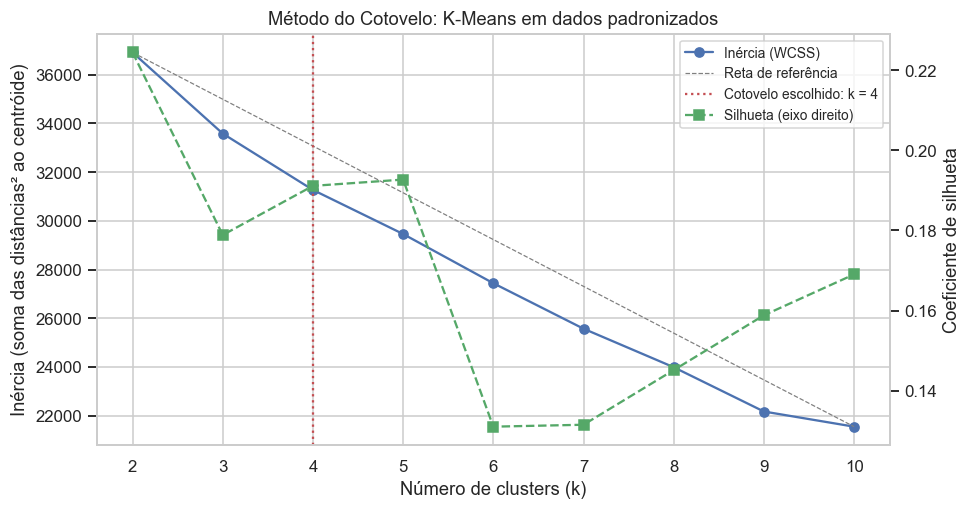

k escolhido pelo cotovelo: 4


,k,inercia,queda_vs_k_anterior,distancia_a_reta,silhueta
0,2,36914.0,NaN,0.000,0.224
1,3,33583.3,3330.7,0.092,0.179
2,4,31270.0,2313.3,0.117,0.191
3,5,29460.2,1809.9,0.110,0.193
4,6,27439.7,2020.5,0.117,0.131
5,7,25572.6,1867.1,0.113,0.132
6,8,23991.0,1581.6,0.091,0.145
7,9,22172.6,1818.4,0.085,0.159
8,10,21550.5,622.1,0.000,0.169


In [14]:
# [IA] Claude: inércia (WCSS) para k = 2..10 e silhueta como critério auxiliar
ks = list(range(2, 11))
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(Z, km.labels_))

# Cotovelo objetivo: ponto da curva mais distante da reta que liga k=2 a k=10
xn = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
yn = (np.array(inercias) - min(inercias)) / (max(inercias) - min(inercias))
distancia = (1 - xn) - yn
K_COTOVELO = ks[int(np.argmax(distancia))]

cotovelo = pd.DataFrame({"k": ks, "inercia": np.round(inercias, 1),
                         "queda_vs_k_anterior": np.r_[np.nan, -np.diff(inercias)].round(1),
                         "distancia_a_reta": distancia.round(3),
                         "silhueta": np.round(silhuetas, 3)})
cotovelo.to_csv(OUT / "cotovelo.csv", index=False)

fig, ax1 = plt.subplots(figsize=(9, 4.8))
ax1.plot(ks, inercias, "o-", c="#4C72B0", label="Inércia (WCSS)")
ax1.plot([ks[0], ks[-1]], [inercias[0], inercias[-1]], "--", c="gray", lw=0.8, label="Reta de referência")
ax1.axvline(K_COTOVELO, c="#C44E52", ls=":", label=f"Cotovelo escolhido: k = {K_COTOVELO}")
ax1.set(xlabel="Número de clusters (k)", ylabel="Inércia (soma das distâncias² ao centróide)",
        title="Método do Cotovelo: K-Means em dados padronizados")
ax2 = ax1.twinx()
ax2.plot(ks, silhuetas, "s--", c="#55A868", label="Silhueta (eixo direito)")
ax2.set_ylabel("Coeficiente de silhueta"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "C8_cotovelo.png"); plt.show()
print("k escolhido pelo cotovelo:", K_COTOVELO)
cotovelo

**Leitura do cotovelo.** A inércia cai de forma quase linear, sem uma "dobra" nítida. Para não depender só do olho, usamos o critério da **maior distância até a reta** que liga k=2 a k=10. A distância é máxima em **k = 4**, empatada com k = 6 (0,117). Pelo princípio da parcimônia, ficamos com o menor k. Os valores de k=4 a k=7 ficam todos muito próximos. Esse cotovelo fraco já indica que os dados **não têm grupos naturais bem separados**. A silhueta, sempre abaixo de 0,25, confirma que os clusters são pouco compactos.

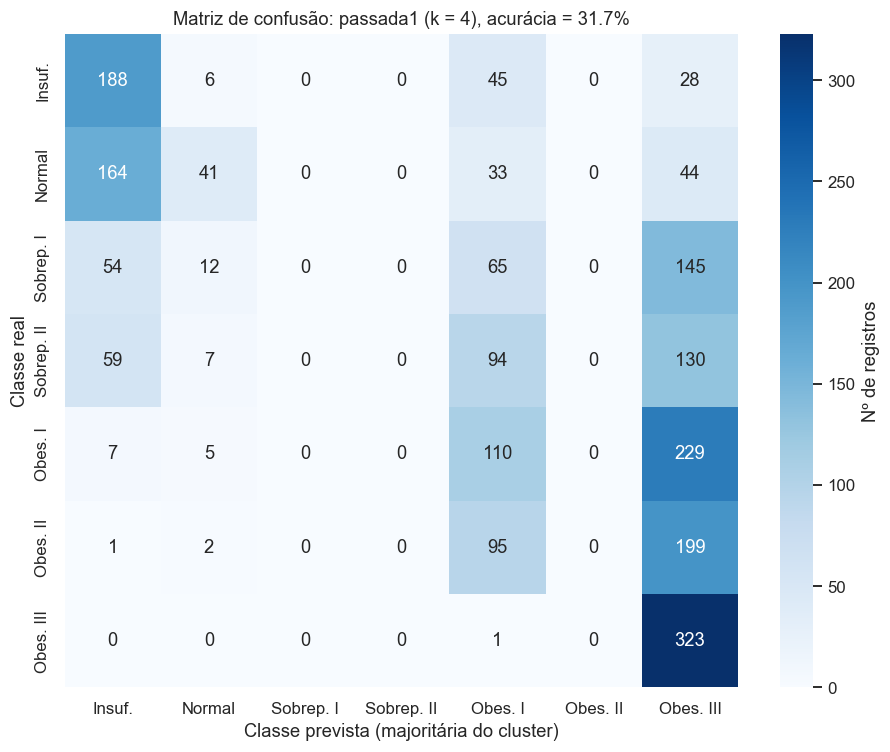

Acurácia (passada1, k=4): 0.317
Mapeamento cluster → classe: {0: 'Obesity_Type_III', 1: 'Obesity_Type_I', 2: 'Insufficient_Weight', 3: 'Normal_Weight'}


NObeyesdad,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,classe_majoritaria,pureza
cluster,,,,,,,,,
0,28,44,145,130,229,199,323,Obesity_Type_III,0.294
1,45,33,65,94,110,95,1,Obesity_Type_I,0.248
2,188,164,54,59,7,1,0,Insufficient_Weight,0.397
3,6,41,12,7,5,2,0,Normal_Weight,0.562


In [15]:
# [IA] Claude: passada 1 com o k do cotovelo
p1 = avaliar(K_COTOVELO, Z, y, "passada1")
p1["composicao"]

In [16]:
p1["metricas"]

,precisao,recall,suporte,prevista_por_algum_cluster
Insufficient_Weight,0.397,0.704,267,True
Normal_Weight,0.562,0.145,282,True
Overweight_Level_I,0.000,0.000,276,False
Overweight_Level_II,0.000,0.000,290,False
Obesity_Type_I,0.248,0.313,351,True
Obesity_Type_II,0.000,0.000,297,False
Obesity_Type_III,0.294,0.997,324,True


## 8. K-Means, passada 2: k = 7, o número real de classes

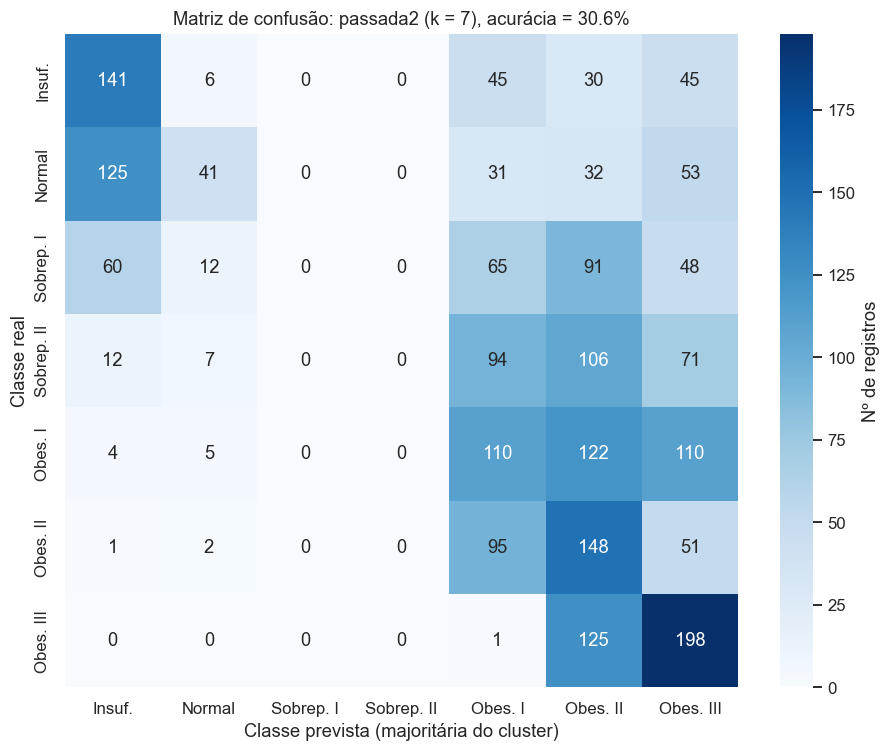

Acurácia (passada2, k=7): 0.306
Mapeamento cluster → classe: {0: 'Normal_Weight', 1: 'Obesity_Type_III', 2: 'Obesity_Type_I', 3: 'Obesity_Type_II', 4: 'Normal_Weight', 5: 'Insufficient_Weight', 6: 'Normal_Weight'}


NObeyesdad,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,classe_majoritaria,pureza
cluster,,,,,,,,,
0,6,31,9,6,2,1,0,Normal_Weight,0.564
1,45,53,48,71,110,51,198,Obesity_Type_III,0.344
2,45,31,65,94,110,95,1,Obesity_Type_I,0.249
3,30,32,91,106,122,148,125,Obesity_Type_II,0.226
4,0,6,1,1,3,0,0,Normal_Weight,0.545
5,141,125,60,12,4,1,0,Insufficient_Weight,0.411
6,0,4,2,0,0,1,0,Normal_Weight,0.571


In [17]:
# [IA] Claude: passada 2 com k igual ao número de classes
K_REAL = y.nunique()
p2 = avaliar(K_REAL, Z, y, "passada2")
p2["composicao"]

In [18]:
p2["metricas"]

,precisao,recall,suporte,prevista_por_algum_cluster
Insufficient_Weight,0.411,0.528,267,True
Normal_Weight,0.562,0.145,282,True
Overweight_Level_I,0.000,0.000,276,False
Overweight_Level_II,0.000,0.000,290,False
Obesity_Type_I,0.249,0.313,351,True
Obesity_Type_II,0.226,0.498,297,True
Obesity_Type_III,0.344,0.611,324,True


## 9. Comparação das duas passadas

In [19]:
# [IA] Claude: tabela comparativa
comp = pd.DataFrame({
    "Passada 1 (cotovelo)": {
        "k": K_COTOVELO, "acurácia": round(p1["acc"], 3),
        "classes nunca previstas": int((~p1["metricas"].prevista_por_algum_cluster).sum()),
        "recall médio (macro)": round(p1["metricas"].recall.mean(), 3),
        "pureza média dos clusters": round(p1["composicao"].pureza.mean(), 3),
        "silhueta": round(silhouette_score(Z, p1["km"].labels_), 3)},
    "Passada 2 (k = 7)": {
        "k": K_REAL, "acurácia": round(p2["acc"], 3),
        "classes nunca previstas": int((~p2["metricas"].prevista_por_algum_cluster).sum()),
        "recall médio (macro)": round(p2["metricas"].recall.mean(), 3),
        "pureza média dos clusters": round(p2["composicao"].pureza.mean(), 3),
        "silhueta": round(silhouette_score(Z, p2["km"].labels_), 3)},
})
comp.to_csv(OUT / "comparacao_passadas.csv")
comp

,Passada 1 (cotovelo),Passada 2 (k = 7)
k,4.000,7.000
acurácia,0.317,0.306
classes nunca previstas,3.000,2.000
recall médio (macro),0.308,0.299
pureza média dos clusters,0.375,0.416
silhueta,0.191,0.132


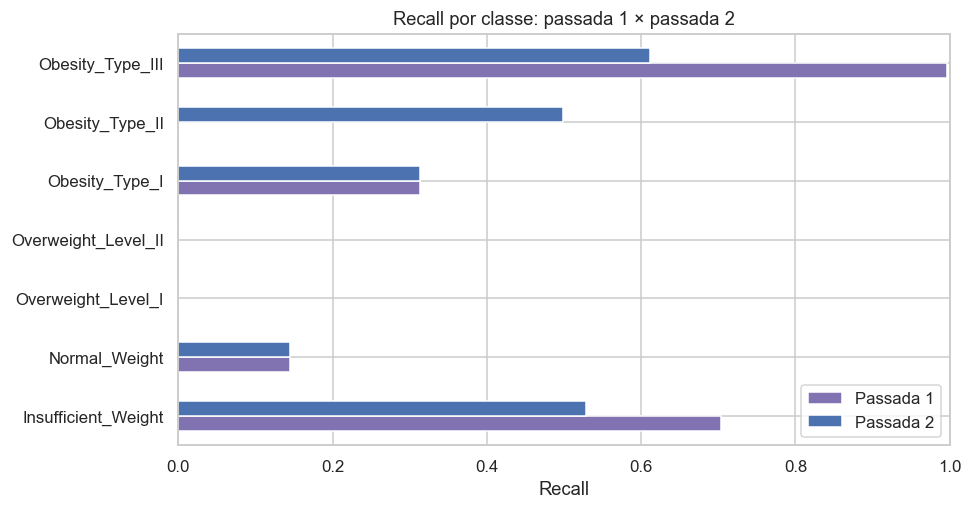

In [20]:
# [IA] Claude: recall por classe nas duas passadas
rc = pd.DataFrame({"Passada 1": p1["metricas"].recall, "Passada 2": p2["metricas"].recall})
ax = rc.plot(kind="barh", figsize=(9, 4.8), color=["#8172B2", "#4C72B0"])
ax.set(title="Recall por classe: passada 1 × passada 2", xlabel="Recall", ylabel="", xlim=(0, 1))
plt.tight_layout(); plt.savefig(FIG / "C9_recall_passadas.png"); plt.show()

### Visualização dos clusters (PCA em 2 dimensões)

Os dados têm 20 dimensões. Para enxergar os clusters, projetamos os dados padronizados nos **2 primeiros componentes principais (PCA)**. A projeção serve só para visualizar, porque o K-Means rodou nas 20 dimensões. Os três painéis usam os mesmos pontos:
- à esquerda, coloridos pela **classe real**;
- no meio, pelos **clusters da passada 1**;
- à direita, pelos **clusters da passada 2**.

Os X marcam os centróides projetados.

Variância explicada: PC1 = 13.8%, PC2 = 11.6%, total = 25.4%


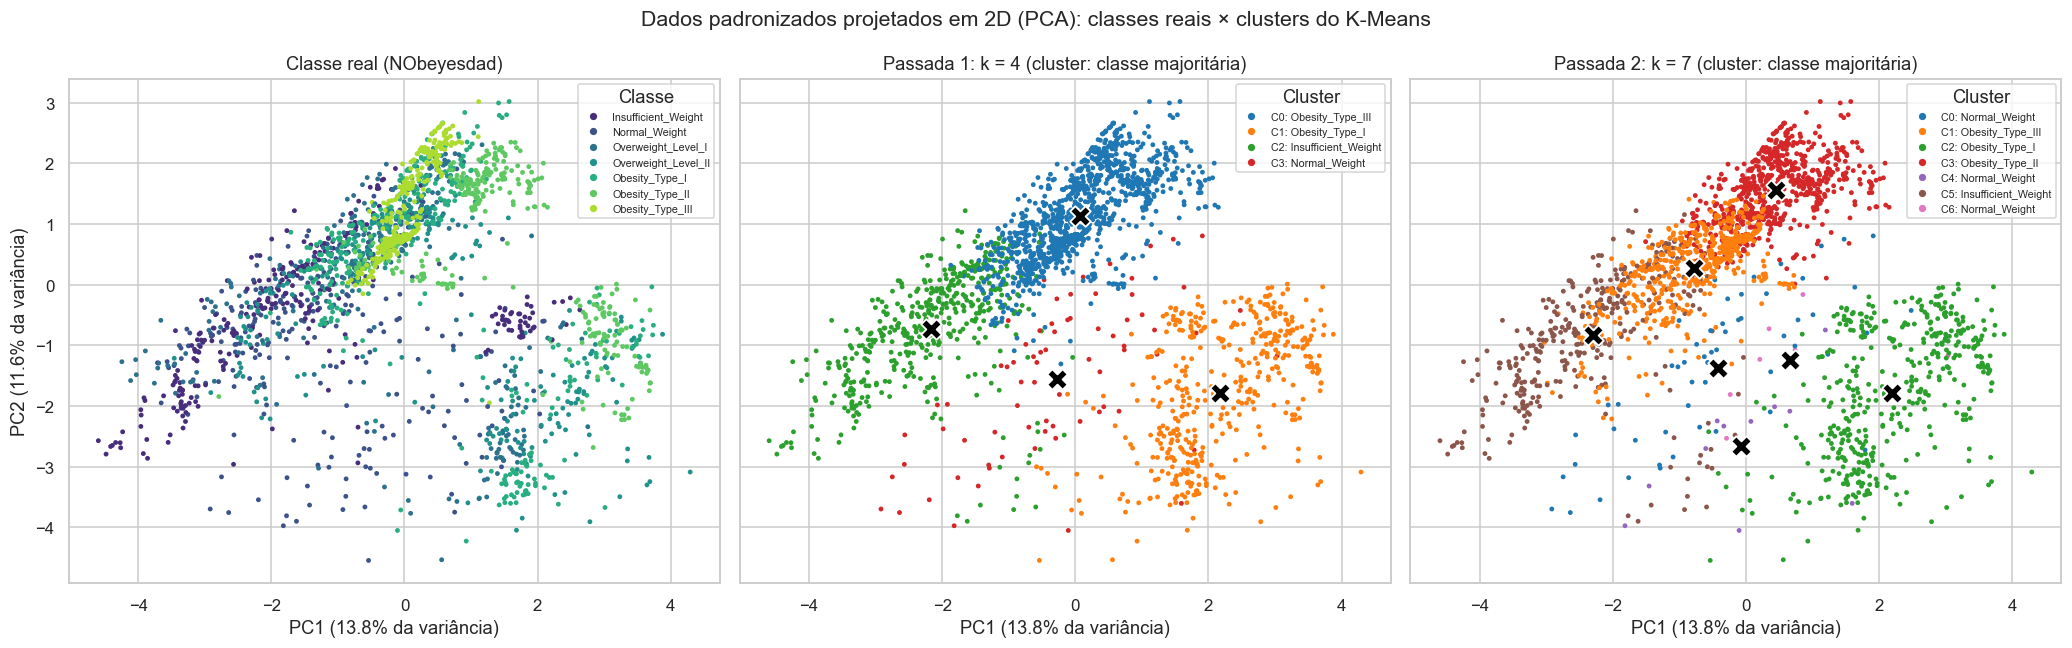

In [21]:
# [IA] Claude: projeção PCA 2D, classes reais × clusters das duas passadas
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=SEED)
P2 = pca.fit_transform(Z)
var = pca.explained_variance_ratio_ * 100
print(f"Variância explicada: PC1 = {var[0]:.1f}%, PC2 = {var[1]:.1f}%, total = {var.sum():.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharex=True, sharey=True)
sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=y, hue_order=ORDEM_CLASSES, palette="viridis",
                s=10, ax=axes[0], linewidth=0)
axes[0].set_title("Classe real (NObeyesdad)")
axes[0].legend(title="Classe", fontsize=7, markerscale=1.5)
for ax, res, nome in [(axes[1], p1, f"Passada 1: k = {K_COTOVELO}"), (axes[2], p2, f"Passada 2: k = {K_REAL}")]:
    lab = res["km"].labels_
    rot = [f"C{c}: {res['mapa'][c]}" for c in lab]
    ordem = [f"C{c}: {res['mapa'][c]}" for c in sorted(set(lab))]
    sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=rot, hue_order=ordem, palette="tab10",
                    s=10, ax=ax, linewidth=0)
    cent = pca.transform(res["km"].cluster_centers_)
    ax.scatter(cent[:, 0], cent[:, 1], marker="X", s=180, c="black", edgecolor="white", linewidth=1.2)
    ax.set_title(f"{nome} (cluster: classe majoritária)")
    ax.legend(title="Cluster", fontsize=7, markerscale=1.5)
for ax in axes:
    ax.set(xlabel=f"PC1 ({var[0]:.1f}% da variância)", ylabel=f"PC2 ({var[1]:.1f}% da variância)")
fig.suptitle("Dados padronizados projetados em 2D (PCA): classes reais × clusters do K-Means", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "C10_clusters_pca.png"); plt.show()

**Leitura.**
- **O plano tem duas massas principais, e elas não correspondem às classes.** A faixa diagonal de cima reúne quem usa transporte público. A nuvem de baixo, à direita, reúne quem usa automóvel, pessoas mais velhas, com média de 32 anos. É essa divisão que o K-Means captura primeiro: o cluster C1 da passada 1 e o C2 da passada 2 são a nuvem do automóvel, e por isso misturam todas as classes de peso.
- **Dentro de cada massa, as classes reais formam um gradiente ordenado,** de Insufficient_Weight a Obesity_Type_III ao longo da diagonal. Não há fronteiras: cada classe encosta na vizinha. É a imagem de um contínuo (IMC), não de grupos separados.
- **Na passada 2, os clusters extras são minúsculos.** C0, C4 e C6 (a pé, moto e bicicleta) aparecem como poucos pontos espalhados no centro. O K-Means gastou 3 dos 7 clusters em categorias raras de transporte, em vez de separar faixas de peso.
- Os dois componentes explicam só 25,4% da variância (13,8% + 11,6%), então parte da sobreposição vem da projeção. A baixa pureza dos clusters, medida nas 20 dimensões, confirma que a mistura também é real.

## 10. Análise complementar: e se o K-Means visse só o que define a classe?

Como o rótulo é uma faixa de IMC, testamos o K-Means com k = 7 em dois conjuntos menores, padronizados da mesma forma:
- (a) só **altura e peso**;
- (b) só o **IMC**.

O teste não substitui as passadas exigidas. Ele serve para entender **por que** as passadas 1 e 2 têm desempenho baixo.

In [22]:
# [IA] Claude: K-Means k=7 com subconjuntos de atributos
Z_hw = StandardScaler().fit_transform(df[["Height", "Weight"]])
Z_imc = StandardScaler().fit_transform(df[["IMC"]])
Z_habitos = StandardScaler().fit_transform(X.drop(columns=["Height", "Weight"]))
comp_ext = {}
for nome, Zs in [("todos_atributos", Z), ("sem_altura_peso", Z_habitos),
                 ("altura_peso", Z_hw), ("so_imc", Z_imc)]:
    lab = KMeans(n_clusters=7, n_init=10, random_state=SEED).fit_predict(Zs)
    _, mapa = mapear_clusters(lab, y)
    pred = pd.Series(lab, index=y.index).map(mapa)
    comp_ext[nome] = {"acurácia": round(accuracy_score(y, pred), 3),
                      "classes nunca previstas": 7 - mapa.nunique()}
comp_ext = pd.DataFrame(comp_ext).T
comp_ext.to_csv(OUT / "analise_complementar_atributos.csv")
comp_ext

,acurácia,classes nunca previstas
todos_atributos,0.306,2.0
sem_altura_peso,0.334,3.0
altura_peso,0.448,1.0
so_imc,0.791,1.0


## 11. Discussão crítica

> Texto redigido com apoio de IA (Claude) a partir dos resultados acima. O grupo revisou e se responsabiliza. Ver `docs/DECLARACAO_IA.pdf`.

**1. Comparação das passadas.**
- A **passada 1** (k = 4) tem acurácia de 31,7% e é limitada por construção: com só 4 clusters, **3 das 7 classes nunca são previstas** (Overweight I, Overweight II e Obesity II) e ficam com recall zero.
- A **passada 2** (k = 7) tem tantos clusters quanto classes, mas a acurácia **não melhora**: fica em 30,6%, um pouco abaixo da passada 1. **Overweight_Level_I e Overweight_Level_II continuam sem nenhum cluster próprio.**
- Mais clusters não fizeram o K-Means "redescobrir" as classes. A pureza média sobe pouco (de 0,375 para 0,416) e a silhueta cai (de 0,191 para 0,132).

**2. O que os clusters realmente separam.** Os perfis médios dos clusters mostram o motivo.
- Na passada 2, **três clusters são definidos pelo meio de transporte**: um só de quem anda a pé (55 pessoas), um só de moto (11) e um só de bicicleta (7). O cluster de quem usa automóvel reúne as pessoas mais velhas, com idade média de 32 anos contra cerca de 22 nos outros.
- Isso é um efeito da padronização sobre dummies raras. A coluna MTRANS_Bike vale 1 em só 0,3% das linhas. Padronizada, esse 1 vira z ≈ 17 e domina a distância euclidiana. Para o K-Means, "andar de bicicleta" pesa mais do que qualquer diferença de peso.
- Nas passadas 1 e 2, os 20 atributos entram com o mesmo peso, mas só altura e peso definem o rótulo, e os hábitos têm correlação fraca com o IMC. O algoritmo encontra a estrutura dominante no conjunto todo dos atributos, como transporte, idade e sexo, que não é a estrutura do IMC.

**3. As classes originais fazem sentido?** Por exemplo, Sobrepeso e Obesidade I são mesmo diferentes?
- Do ponto de vista **clínico**, sim. São faixas de IMC da OMS (25 a 29,9 e 30 a 34,9) com riscos de saúde diferentes.
- Do ponto de vista **dos dados**, não como grupos naturais. São cortes arbitrários num **contínuo**. Uma pessoa com IMC 29,8 e outra com 30,1 são quase idênticas em todos os atributos, mas ficam em classes diferentes. Não existe uma "lacuna" de densidade entre as faixas que o K-Means possa encontrar.
- Neste dataset, a fronteira é ainda mais borrada. O boxplot do IMC mostra **sobreposição entre classes vizinhas** (Overweight I e II, Obesity II e III), provavelmente por causa dos 77% de registros sintéticos gerados por SMOTE, que interpola pontos entre vizinhos.
- Por isso **Sobrepeso I e Sobrepeso II nunca são classe majoritária de um cluster**: elas ficam "espremidas" entre Normal e Obesidade I, e seus pontos se espalham por clusters de classes vizinhas. Na prática, os dados sustentam no máximo 3 ou 4 grupos amplos (abaixo do peso ou normal, sobrepeso, obesidade e obesidade grave), o que coincide com o cotovelo em k = 4.

**4. A análise complementar confirma.** Os resultados com k = 7 e conjuntos diferentes de atributos:
- só altura e peso: acurácia de **44,8%**;
- só o IMC: **79,1%**, porque o K-Means em 1 dimensão praticamente reproduz os cortes de faixa;
- sem altura e peso, só com os hábitos: **33,4%**, o nível das passadas principais. **A informação que separa as classes está no IMC, não nos hábitos.** Os hábitos alimentares e de atividade física, sozinhos, não formam grupos que correspondam às faixas de obesidade.

**5. Limitações.**
- K-Means supõe clusters esféricos e de tamanho parecido, e a distância euclidiana sobre variáveis binárias e one-hot é uma aproximação. Como visto no item 2, dummies raras distorcem o resultado. Agrupar as categorias raras de MTRANS, ou usar um algoritmo próprio para dados mistos, como K-Prototypes, seriam melhorias possíveis.
- O resultado depende da semente; usamos `random_state = 42` e `n_init = 10`.
- A maioria dos dados é sintética, então as conclusões valem para este dataset e não necessariamente para a população.

**Conclusão.** O K-Means não recupera as 7 classes, nem com k = 7. A explicação não é falha do algoritmo: as classes são **cortes de um contínuo (IMC)**, e não grupos naturais. Os dados indicam, no máximo, 3 ou 4 grupos amplos. Sobrepeso e Obesidade I são categorias úteis clinicamente, mas não aparecem como grupos distintos nos dados.